In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [2]:
import os
import pandas as pd

DATA_DIR = "pc_parts"

categories = sorted(os.listdir(DATA_DIR))

data = []

for category in categories:
    folder = os.path.join(DATA_DIR, category)

    if os.path.isdir(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            )
        ]

        data.append({
            "category": category,
            "images": len(images)
        })

df = pd.DataFrame(data)

display(df)
print("Всего изображений:", df["images"].sum())

,category,images
0,cables,298
1,case,282
2,cpu,142
3,gpu,156
4,hdd,262
5,headset,264
6,keyboard,268
7,microphone,214
8,monitor,256
9,motherboard,241


Всего изображений: 3279


In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("pc_parts")

records = []

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        for image_path in folder.iterdir():
            if image_path.suffix.lower() in [
                ".jpg", ".jpeg", ".png", ".webp"
            ]:
                records.append({
                    "filepath": str(image_path.resolve()),
                    "category": folder.name
                })

df_images = pd.DataFrame(records)

print(df_images.shape)
display(df_images.head())

(3279, 2)


,filepath,category
0,C:\Users\user\Desktop\ml_jupiter\newprediction...,cables
1,C:\Users\user\Desktop\ml_jupiter\newprediction...,cables
2,C:\Users\user\Desktop\ml_jupiter\newprediction...,cables
3,C:\Users\user\Desktop\ml_jupiter\newprediction...,cables
4,C:\Users\user\Desktop\ml_jupiter\newprediction...,cables


In [4]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_images,
    test_size=0.30,
    random_state=42,
    stratify=df_images["category"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["category"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 2295
Validation: 492
Test: 492


In [5]:
distribution = pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Test": test_df["category"].value_counts()
}).fillna(0).astype(int)

display(distribution)

,Train,Validation,Test
category,,,
cables,209,45,44
case,197,43,42
cpu,99,21,22
gpu,109,23,24
hdd,183,39,40
headset,185,40,39
keyboard,188,40,40
microphone,150,32,32
monitor,179,38,39


In [6]:
import tensorflow as tf
import numpy as np
import json

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

class_names = sorted(df_images["category"].unique())
num_classes = len(class_names)

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print(class_to_index)
print("Количество классов:", num_classes)

{'cables': 0, 'case': 1, 'cpu': 2, 'gpu': 3, 'hdd': 4, 'headset': 5, 'keyboard': 6, 'microphone': 7, 'monitor': 8, 'motherboard': 9, 'mouse': 10, 'ram': 11, 'speakers': 12, 'webcam': 13}
Количество классов: 14


In [7]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

In [8]:
def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].astype(str).values

    labels = dataframe["category"].map(
        class_to_index
    ).astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [9]:
for images, labels in train_ds.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.shape)

Images: (32, 224, 224, 3)
Labels: (32,)


In [14]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [15]:
inputs = layers.Input(shape=(224, 224, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)

x = layers.Rescaling(
    scale=1/127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_flip_1 (RandomFlip)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom_1 (RandomZoom)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 14)                  │           1,806 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,758 (9.25 MB)

 Trainable params: 165,774 (647.55 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
# Работа с файлами и данными
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Разделение данных и оценка модели
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Работа с изображениями
from PIL import Image

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Все библиотеки импортированы!")

TensorFlow: 2.21.0
GPU: []
Все библиотеки импортированы!


In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
import os

os.makedirs("models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "models/best_electronics.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

In [18]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


72/72 ━━━━━━━━━━━━━━━━━━━━ 52s 558ms/step - accuracy: 0.5020 - loss: 1.6383 - val_accuracy: 0.7154 - val_loss: 1.0369 - learning_rate: 0.0010
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 36s 481ms/step - accuracy: 0.7072 - loss: 1.0016 - val_accuracy: 0.7419 - val_loss: 0.9649 - learning_rate: 0.0010
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 39s 449ms/step - accuracy: 0.7586 - loss: 0.8020 - val_accuracy: 0.7276 - val_loss: 0.9313 - learning_rate: 0.0010
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 454ms/step - accuracy: 0.7887 - loss: 0.7141 - val_accuracy: 0.7337 - val_loss: 0.9211 - learning_rate: 0.0010
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 41s 452ms/step - accuracy: 0.7943 - loss: 0.6619 - val_accuracy: 0.7480 - val_loss: 0.9172 - learning_rate: 0.0010
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 489ms/step - accuracy: 0.8270 - loss: 0.5742 - val_accuracy: 0.7602 - val_loss: 0.9553 - learning_rate: 0.0010
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 34s 456ms/step - accuracy: 0.8444 - loss: 0.5291 - val_

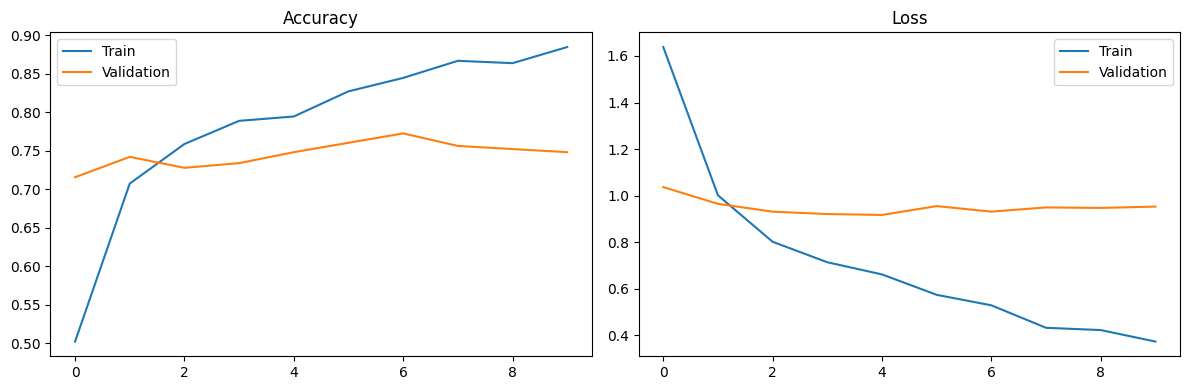

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
model = tf.keras.models.load_model(
    "models/best_electronics.keras"
)

In [21]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 346ms/step - accuracy: 0.7337 - loss: 0.9510
Test Accuracy: 73.37%
Test Loss: 0.9510


In [22]:
import json
import tensorflow as tf

# Сохраняем модель, которую только что тестировали
model.save("electronics_ai_v2.keras")

# Сохраняем порядок классов
with open("classes.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=4)

print("Модель сохранена!")
print("Классы:", class_names)

Модель сохранена!
Классы: ['cables', 'case', 'cpu', 'gpu', 'hdd', 'headset', 'keyboard', 'microphone', 'monitor', 'motherboard', 'mouse', 'ram', 'speakers', 'webcam']
